# 🏠 Classificateur de Maisons — EfficientNetB3
> **Dataset** : `Luxury` / `Normal` / `Old`  
> **Modèle** : EfficientNetB3 (transfer learning + fine-tuning 3 phases)  
> **Objectif** : Améliorer la précision par rapport à MobileNetV2


## Étape 0 — Imports & Configuration

In [1]:
import os, shutil, warnings
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix
from tensorflow.keras import layers, models, callbacks, regularizers
from tensorflow.keras.applications import EfficientNetB3
from tensorflow.keras.preprocessing.image import ImageDataGenerator

warnings.filterwarnings('ignore')

# ── Chemin du dataset
DATASET_PATH = r'C:\Users\MSI\Desktop\projet\dataset'
IMG_SIZE     = (300, 300)   # taille native EfficientNetB3
BATCH_SIZE   = 16
CLASS_NAMES  = ['Luxury', 'Normal', 'Old']

print("✅ Imports OK")
print(f"📁 Dataset : {DATASET_PATH}")
print(f"🖼️  Taille  : {IMG_SIZE}")
print(f"GPU disponible : {tf.config.list_physical_devices('GPU')}")


✅ Imports OK
📁 Dataset : C:\Users\MSI\Desktop\projet\dataset
🖼️  Taille  : (300, 300)
GPU disponible : []


## Étape 1 — Vérification du Dataset

In [2]:
for cls in CLASS_NAMES:
    path = os.path.join(DATASET_PATH, cls)
    if os.path.exists(path):
        n = len([f for f in os.listdir(path) if f.lower().endswith(('.jpg','.jpeg','.png','.webp'))])
        print(f"  📂 {cls:8s} → {n} images")
    else:
        print(f"  ❌ Dossier manquant : {path}")


  📂 Luxury   → 168 images
  📂 Normal   → 119 images
  📂 Old      → 147 images


## Étape 2 — Aperçu des Images

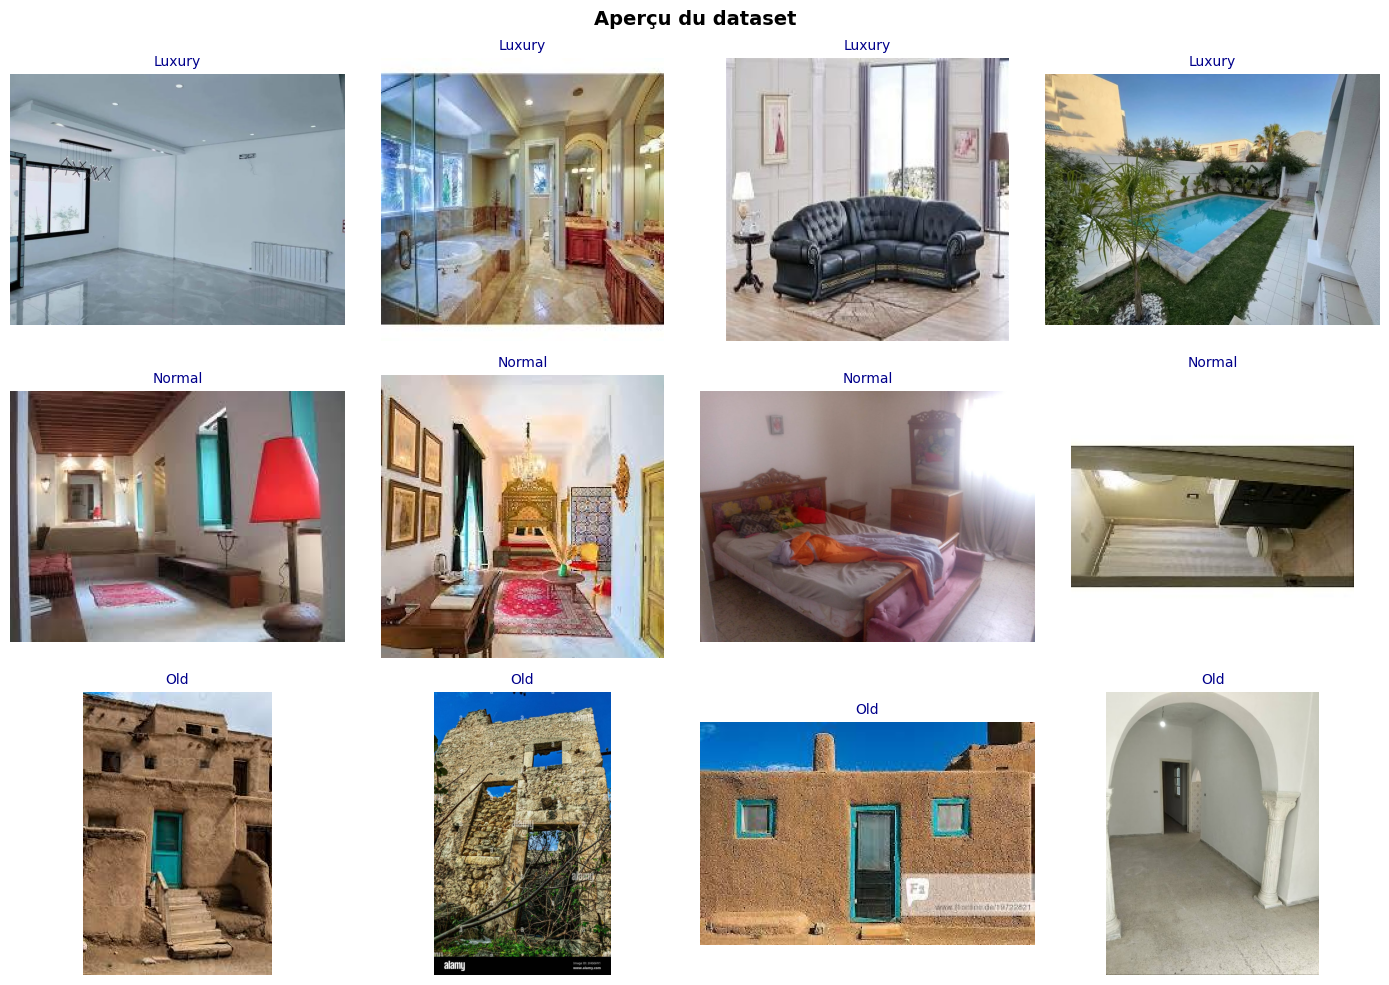

In [3]:
fig, axes = plt.subplots(3, 4, figsize=(14, 10))
for row, cls in enumerate(CLASS_NAMES):
    cls_path = os.path.join(DATASET_PATH, cls)
    images   = [f for f in os.listdir(cls_path) if f.lower().endswith(('.jpg','.jpeg','.png'))][:4]
    for col, fname in enumerate(images):
        img = plt.imread(os.path.join(cls_path, fname))
        axes[row, col].imshow(img)
        axes[row, col].set_title(cls, fontsize=10, color='darkblue')
        axes[row, col].axis('off')
plt.suptitle("Aperçu du dataset", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('dataset_preview.png', dpi=120)
plt.show()


## Étape 3 — Data Augmentation
> ⚠️ **EfficientNetB3 n'a PAS besoin de `rescale=1./255`**  
> Son preprocessing interne est appelé via `tf.keras.applications.efficientnet.preprocess_input`


In [4]:
# ── Preprocessing spécifique EfficientNetB3
from tensorflow.keras.applications.efficientnet import preprocess_input

def preprocess_fn(x):
    return preprocess_input(x)

# ── Augmentation entraînement (plus riche)
train_datagen = ImageDataGenerator(
    preprocessing_function = preprocess_fn,
    validation_split       = 0.2,
    rotation_range         = 25,
    width_shift_range      = 0.2,
    height_shift_range     = 0.2,
    shear_range            = 0.2,
    zoom_range             = 0.25,
    horizontal_flip        = True,
    brightness_range       = [0.75, 1.25],
    channel_shift_range    = 20.0,
    fill_mode              = 'reflect'
)

# ── Validation : preprocessing seulement
val_datagen = ImageDataGenerator(
    preprocessing_function = preprocess_fn,
    validation_split       = 0.2
)

train_data = train_datagen.flow_from_directory(
    DATASET_PATH,
    target_size  = IMG_SIZE,
    batch_size   = BATCH_SIZE,
    class_mode   = 'categorical',
    subset       = 'training',
    shuffle      = True
)

val_data = val_datagen.flow_from_directory(
    DATASET_PATH,
    target_size  = IMG_SIZE,
    batch_size   = BATCH_SIZE,
    class_mode   = 'categorical',
    subset       = 'validation',
    shuffle      = False
)

print("\n✅ Classes détectées :", train_data.class_indices)
print(f"   Train  : {train_data.samples} images")
print(f"   Val    : {val_data.samples} images")


Found 344 images belonging to 3 classes.
Found 84 images belonging to 3 classes.

✅ Classes détectées : {'Luxury': 0, 'Normal': 1, 'Old': 2}
   Train  : 344 images
   Val    : 84 images


## Étape 4 — Class Weights (équilibrage des classes)

In [5]:
y_train = train_data.classes
weights = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
class_weight = dict(enumerate(weights))

print("⚖️  Class weights :")
for idx, cls in enumerate(CLASS_NAMES):
    print(f"   {cls:8s} → {class_weight[idx]:.3f}")


⚖️  Class weights :
   Luxury   → 0.856
   Normal   → 1.194
   Old      → 1.006


## Étape 5 — Construction du Modèle EfficientNetB3

In [6]:
# ── Base EfficientNetB3 gelée
base_model = EfficientNetB3(
    weights      = 'imagenet',
    include_top  = False,
    input_shape  = (*IMG_SIZE, 3)
)
base_model.trainable = False

# ── Tête de classification
inputs = tf.keras.Input(shape=(*IMG_SIZE, 3))
x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.BatchNormalization()(x)
x = layers.Dense(256, activation='relu',
                 kernel_regularizer=regularizers.l2(0.001))(x)
x = layers.Dropout(0.5)(x)
x = layers.Dense(128, activation='relu',
                 kernel_regularizer=regularizers.l2(0.001))(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(3, activation='softmax')(x)

model = tf.keras.Model(inputs, outputs)

model.compile(
    optimizer = tf.keras.optimizers.Adam(1e-3),
    loss      = 'categorical_crossentropy',
    metrics   = ['accuracy']
)

model.summary()
print(f"\n📊 Paramètres entraînables : {model.trainable_variables.__len__()}")


43941136/43941136 ━━━━━━━━━━━━━━━━━━━━ 31s 1us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 300, 300, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb3 (Functional)     │ (None, 10, 10, 1536)   │    10,783,535 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1536)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1536)           │         6,144 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       393,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,216,434 (42.79 MB)

 Trainable params: 429,827 (1.64 MB)

 Non-trainable params: 10,786,607 (41.15 MB)


📊 Paramètres entraînables : 8


## Étape 6 — Callbacks

In [7]:
cb = [
    callbacks.EarlyStopping(
        patience            = 10,
        restore_best_weights= True,
        monitor             = 'val_accuracy',
        verbose             = 1
    ),
    callbacks.ModelCheckpoint(
        'best_model_efficientnetb3.keras',
        save_best_only = True,
        monitor        = 'val_accuracy',
        verbose        = 1
    ),
    callbacks.ReduceLROnPlateau(
        patience = 5,
        factor   = 0.4,
        min_lr   = 1e-7,
        verbose  = 1,
        monitor  = 'val_loss'
    )
]
print("✅ Callbacks prêts")


✅ Callbacks prêts


## Étape 7 — Phase 1 : Entraînement de la Tête (base gelée)

In [8]:
print("=" * 55)
print("  PHASE 1 — Tête seulement (base EfficientNetB3 gelée)")
print("=" * 55)

history1 = model.fit(
    train_data,
    validation_data = val_data,
    epochs          = 30,
    callbacks       = cb,
    class_weight    = class_weight
)

print(f"\n✅ Meilleure val_accuracy Phase 1 : {max(history1.history['val_accuracy'])*100:.1f}%")


  PHASE 1 — Tête seulement (base EfficientNetB3 gelée)
Epoch 1/30
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 770ms/step - accuracy: 0.4677 - loss: 1.9157
Epoch 1: val_accuracy improved from -inf to 0.59524, saving model to best_model_efficientnetb3.keras
22/22 ━━━━━━━━━━━━━━━━━━━━ 33s 1s/step - accuracy: 0.4701 - loss: 1.9140 - val_accuracy: 0.5952 - val_loss: 1.5192 - learning_rate: 0.0010
Epoch 2/30
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 865ms/step - accuracy: 0.6590 - loss: 1.5242
Epoch 2: val_accuracy improved from 0.59524 to 0.66667, saving model to best_model_efficientnetb3.keras
22/22 ━━━━━━━━━━━━━━━━━━━━ 23s 1s/step - accuracy: 0.6604 - loss: 1.5183 - val_accuracy: 0.6667 - val_loss: 1.4365 - learning_rate: 0.0010
Epoch 3/30
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 800ms/step - accuracy: 0.7393 - loss: 1.2829
Epoch 3: val_accuracy did not improve from 0.66667
22/22 ━━━━━━━━━━━━━━━━━━━━ 21s 969ms/step - accuracy: 0.7408 - loss: 1.2794 - val_accuracy: 0.6310 - val_loss: 1.4885 - learning_rate: 0.0010
Epoch 4/30


## Étape 8 — Phase 2 : Fine-tuning Léger (30 dernières couches)

In [9]:
print("=" * 55)
print("  PHASE 2 — Fine-tuning léger (30 couches)")
print("=" * 55)

base_model.trainable = True
for layer in base_model.layers[:-30]:
    layer.trainable = False

trainable_count = sum(1 for l in base_model.layers if l.trainable)
print(f"   Couches dégelées : {trainable_count} / {len(base_model.layers)}")

model.compile(
    optimizer = tf.keras.optimizers.Adam(1e-5),
    loss      = 'categorical_crossentropy',
    metrics   = ['accuracy']
)

history2 = model.fit(
    train_data,
    validation_data = val_data,
    epochs          = 20,
    callbacks       = cb,
    class_weight    = class_weight
)

print(f"\n✅ Meilleure val_accuracy Phase 2 : {max(history2.history['val_accuracy'])*100:.1f}%")


  PHASE 2 — Fine-tuning léger (30 couches)
   Couches dégelées : 30 / 385
Epoch 1/20
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 838ms/step - accuracy: 0.6380 - loss: 1.5107
Epoch 1: val_accuracy did not improve from 0.66667
22/22 ━━━━━━━━━━━━━━━━━━━━ 34s 1s/step - accuracy: 0.6376 - loss: 1.5126 - val_accuracy: 0.6429 - val_loss: 1.4321 - learning_rate: 1.0000e-05
Epoch 2/20
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 867ms/step - accuracy: 0.6715 - loss: 1.5308
Epoch 2: val_accuracy did not improve from 0.66667
22/22 ━━━━━━━━━━━━━━━━━━━━ 22s 1s/step - accuracy: 0.6711 - loss: 1.5315 - val_accuracy: 0.6667 - val_loss: 1.4350 - learning_rate: 1.0000e-05
Epoch 3/20
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 843ms/step - accuracy: 0.6999 - loss: 1.4443
Epoch 3: val_accuracy did not improve from 0.66667
22/22 ━━━━━━━━━━━━━━━━━━━━ 22s 992ms/step - accuracy: 0.6997 - loss: 1.4461 - val_accuracy: 0.6667 - val_loss: 1.4384 - learning_rate: 1.0000e-05
Epoch 4/20
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 855ms/step - accuracy: 0.6788 - loss: 1.50

## Étape 9 — Phase 3 : Fine-tuning Profond (modèle entier)

In [10]:
print("=" * 55)
print("  PHASE 3 — Fine-tuning complet (lr très faible)")
print("=" * 55)

base_model.trainable = True   # tout dégeler

model.compile(
    optimizer = tf.keras.optimizers.Adam(1e-6),
    loss      = 'categorical_crossentropy',
    metrics   = ['accuracy']
)

cb_phase3 = [
    callbacks.EarlyStopping(patience=8, restore_best_weights=True, monitor='val_accuracy', verbose=1),
    callbacks.ModelCheckpoint('best_model_efficientnetb3.keras', save_best_only=True, monitor='val_accuracy', verbose=1),
    callbacks.ReduceLROnPlateau(patience=4, factor=0.3, min_lr=1e-8, verbose=1, monitor='val_loss')
]

history3 = model.fit(
    train_data,
    validation_data = val_data,
    epochs          = 15,
    callbacks       = cb_phase3,
    class_weight    = class_weight
)

print(f"\n✅ Meilleure val_accuracy Phase 3 : {max(history3.history['val_accuracy'])*100:.1f}%")


  PHASE 3 — Fine-tuning complet (lr très faible)
Epoch 1/15
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 839ms/step - accuracy: 0.6624 - loss: 1.4199
Epoch 1: val_accuracy improved from -inf to 0.66667, saving model to best_model_efficientnetb3.keras
22/22 ━━━━━━━━━━━━━━━━━━━━ 36s 1s/step - accuracy: 0.6627 - loss: 1.4221 - val_accuracy: 0.6667 - val_loss: 1.4382 - learning_rate: 1.0000e-06
Epoch 2/15
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 876ms/step - accuracy: 0.6590 - loss: 1.5435
Epoch 2: val_accuracy did not improve from 0.66667
22/22 ━━━━━━━━━━━━━━━━━━━━ 22s 1s/step - accuracy: 0.6591 - loss: 1.5417 - val_accuracy: 0.6548 - val_loss: 1.4428 - learning_rate: 1.0000e-06
Epoch 3/15
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 870ms/step - accuracy: 0.6749 - loss: 1.4226
Epoch 3: val_accuracy did not improve from 0.66667
22/22 ━━━━━━━━━━━━━━━━━━━━ 22s 1s/step - accuracy: 0.6736 - loss: 1.4261 - val_accuracy: 0.6429 - val_loss: 1.4490 - learning_rate: 1.0000e-06
Epoch 4/15
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 852ms/step - accurac

## Étape 10 — Courbes d'Apprentissage (3 phases)

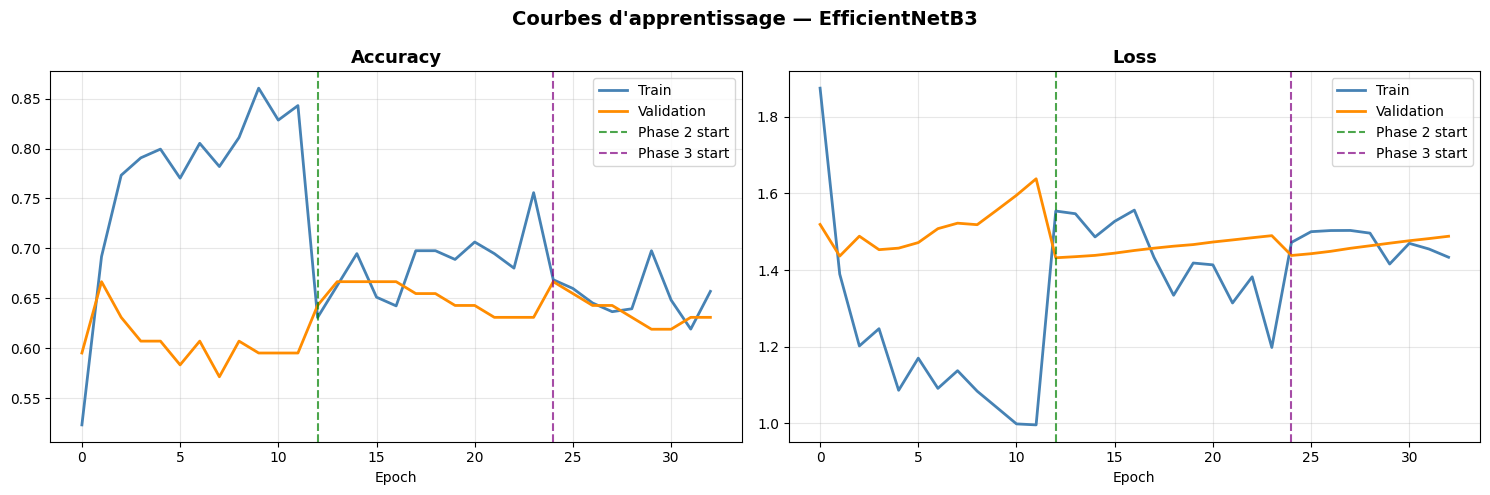


📊 Meilleure val_accuracy globale : 66.67%
📊 Epoch du meilleur résultat     : 2


In [11]:
# Combiner les 3 phases
acc     = history1.history['accuracy']     + history2.history['accuracy']     + history3.history['accuracy']
val_acc = history1.history['val_accuracy'] + history2.history['val_accuracy'] + history3.history['val_accuracy']
loss    = history1.history['loss']         + history2.history['loss']         + history3.history['loss']
val_loss= history1.history['val_loss']     + history2.history['val_loss']     + history3.history['val_loss']

p1 = len(history1.history['accuracy'])
p2 = p1 + len(history2.history['accuracy'])

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for ax, train_v, val_v, title in [
    (axes[0], acc,  val_acc,  'Accuracy'),
    (axes[1], loss, val_loss, 'Loss')
]:
    ax.plot(train_v, label='Train',      color='steelblue',  linewidth=2)
    ax.plot(val_v,   label='Validation', color='darkorange', linewidth=2)
    ax.axvline(x=p1, color='green',  linestyle='--', alpha=0.7, label='Phase 2 start')
    ax.axvline(x=p2, color='purple', linestyle='--', alpha=0.7, label='Phase 3 start')
    ax.set_title(title, fontsize=13, fontweight='bold')
    ax.set_xlabel('Epoch')
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.suptitle('Courbes d\'apprentissage — EfficientNetB3', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('learning_curves_efficientnetb3.png', dpi=150)
plt.show()

best_val = max(val_acc)
print(f"\n📊 Meilleure val_accuracy globale : {best_val*100:.2f}%")
print(f"📊 Epoch du meilleur résultat     : {np.argmax(val_acc)+1}")


## Étape 11 — Évaluation Finale

6/6 ━━━━━━━━━━━━━━━━━━━━ 7s 870ms/step

  RAPPORT DE CLASSIFICATION
              precision    recall  f1-score   support

      Luxury      0.742     0.697     0.719        33
      Normal      0.500     0.478     0.489        23
         Old      0.710     0.786     0.746        28

    accuracy                          0.667        84
   macro avg      0.651     0.654     0.651        84
weighted avg      0.665     0.667     0.665        84



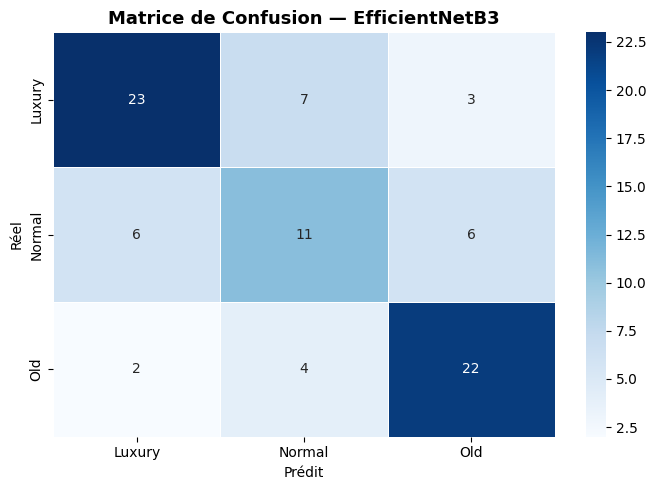

In [12]:
# Recharger le meilleur modèle sauvegardé
model = tf.keras.models.load_model('best_model_efficientnetb3.keras')

val_data.reset()
y_pred     = np.argmax(model.predict(val_data, verbose=1), axis=1)
y_true     = val_data.classes
class_names = list(val_data.class_indices.keys())

print("\n" + "="*55)
print("  RAPPORT DE CLASSIFICATION")
print("="*55)
print(classification_report(y_true, y_pred, target_names=class_names, digits=3))

# Matrice de confusion
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names,
            linewidths=0.5)
plt.title('Matrice de Confusion — EfficientNetB3', fontsize=13, fontweight='bold')
plt.ylabel('Réel')
plt.xlabel('Prédit')
plt.tight_layout()
plt.savefig('confusion_matrix_efficientnetb3.png', dpi=150)
plt.show()


## Étape 12 — Prédiction sur une Image

In [13]:
from tensorflow.keras.preprocessing import image as keras_image
from tensorflow.keras.applications.efficientnet import preprocess_input

def predict_image(img_path, model, class_names):
    img        = keras_image.load_img(img_path, target_size=IMG_SIZE)
    img_array  = keras_image.img_to_array(img)
    img_array  = preprocess_input(np.expand_dims(img_array, axis=0))

    pred       = model.predict(img_array, verbose=0)[0]
    best_idx   = np.argmax(pred)
    best_cls   = class_names[best_idx]
    confidence = pred[best_idx] * 100

    # Affichage
    colors = {'Luxury': 'gold', 'Normal': 'steelblue', 'Old': 'crimson'}
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

    ax1.imshow(keras_image.load_img(img_path))
    ax1.set_title(f"Prédit : {best_cls} ({confidence:.1f}%)",
                  fontsize=13, color=colors.get(best_cls, 'black'), fontweight='bold')
    ax1.axis('off')

    bars = ax2.barh(class_names, [pred[i]*100 for i in range(len(class_names))],
                    color=[colors.get(c,'gray') for c in class_names])
    ax2.set_xlim(0, 100)
    ax2.set_xlabel('Probabilité (%)')
    ax2.set_title('Distribution des probabilités', fontsize=11)
    for bar, val in zip(bars, [pred[i]*100 for i in range(len(class_names))]):
        ax2.text(val + 1, bar.get_y() + bar.get_height()/2,
                 f'{val:.1f}%', va='center', fontsize=10)

    plt.tight_layout()
    plt.show()

    # Alerte Old
    if best_cls == 'Old':
        print("\n" + "🚨"*20)
        print("  ALERTE : MAISON ANCIENNE DÉTECTÉE !")
        print("  → Inspection structurelle recommandée")
        print("  → Vérification électrique et plomberie")
        print("🚨"*20)

    return best_cls, confidence

# ── Exemple d'utilisation
# predict_image(r"C:\Users\MSI\Desktop\projet\dataset\Old\exemple.jpg", model, CLASS_NAMES)


## Étape 13 — Sauvegarde du Modèle Final

In [14]:
model.save('house_classifier_efficientnetb3_final.keras')
print("✅ Modèle sauvegardé : house_classifier_efficientnetb3_final.keras")

# Résumé
print("\n" + "="*55)
print("  RÉSUMÉ FINAL")
print("="*55)
print(f"  Modèle      : EfficientNetB3")
print(f"  Input size  : {IMG_SIZE}")
print(f"  Classes     : {CLASS_NAMES}")
print(f"  Phases      : 3 (tête → fine-tuning léger → complet)")
print(f"  Val Accuracy: {max(val_acc)*100:.2f}%")
print("="*55)


✅ Modèle sauvegardé : house_classifier_efficientnetb3_final.keras

  RÉSUMÉ FINAL
  Modèle      : EfficientNetB3
  Input size  : (300, 300)
  Classes     : ['Luxury', 'Normal', 'Old']
  Phases      : 3 (tête → fine-tuning léger → complet)
  Val Accuracy: 66.67%
